# Modelo — prever readmissão em < 30 dias

> ### Resumo executivo
> - **Objetivo:** um escore de risco de readmissão em até 30 dias para priorizar quem recebe intervenção na alta.
> - **Método:** regressão logística e gradient boosting, com treino e teste **separados por paciente**
>   e métricas adequadas a classes desbalanceadas (11% de readmissões).
> - **Resultado:** gradient boosting com **ROC-AUC 0,686** (base aleatória: 0,50). Os **20% de maior risco
>   concentram 41% das readmissões**; no decil mais alto, 28,4% voltam, contra 3,6% no mais baixo.
> - **O que mais pesa:** destino da alta e histórico de internações.
> - **Equidade:** desempenho parecido entre raças e gêneros, mas **menor em pacientes com 80 anos ou mais**.
> - **Uso proposto:** ferramenta de **priorização** assistencial, nunca de decisão isolada (seção 8).

**Objetivo:** dar a cada internação um **escore de risco** de readmissão em < 30 dias,
para priorizar quem recebe intervenção na alta (educação em saúde, retorno precoce,
contato telefônico).

**Decisões de método (e por quê):**

| Decisão | Motivo |
|---|---|
| Treino/teste separados **por paciente** | O mesmo paciente aparece em várias internações. Se ele estiver nos dois lados, o modelo "decora" o paciente e a métrica fica otimista. |
| Métricas **ROC-AUC** e **PR-AUC**, não acurácia | Só 11% são readmitidos: prever "ninguém volta" já dá 89% de acurácia. |
| `class_weight="balanced"` | Faz o modelo dar mais peso aos poucos casos positivos. |
| Base de comparação + 2 modelos | Regressão logística (interpretável) e gradient boosting (captura não linearidades). |

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from etl.rotulos import nome_feature, nome_variavel, rotulo  # nomes em portugues nos graficos
FIGURAS = RAIZ / "reports" / "figures"
MODELOS = RAIZ / "models"
MODELOS.mkdir(exist_ok=True)
SEMENTE = 42

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
TINTA, TINTA_2, SUPERFICIE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "figure.dpi": 110,
})

df = pd.read_csv(RAIZ / "data-processed" / "dataset_modelo.csv")
y = df["readmit_30"]
grupos = df["patient_nbr"]
X = df.drop(columns=["readmit_30", "patient_nbr"])

numericas = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
categoricas = [c for c in X.columns if c not in numericas]
print(f"{X.shape[0]:,} internacoes | {len(numericas)} numericas | {len(categoricas)} categoricas")

99,340 internacoes | 16 numericas | 23 categoricas


## 1. Separação treino / teste por paciente (80 / 20)

In [2]:
divisor = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_treino, idx_teste = next(divisor.split(X, y, groups=grupos))
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
g_treino = grupos.iloc[idx_treino]

assert set(grupos.iloc[idx_treino]).isdisjoint(grupos.iloc[idx_teste]), "Paciente nos dois lados!"
pd.DataFrame({
    "Internações": [len(y_treino), len(y_teste)],
    "Pacientes": [grupos.iloc[idx_treino].nunique(), grupos.iloc[idx_teste].nunique()],
    "Taxa de readmissão": [y_treino.mean(), y_teste.mean()],
}, index=["Treino", "Teste"]).style.format(
    {"Internações": "{:,}", "Pacientes": "{:,}", "Taxa de readmissão": "{:.1%}"})

,Internações,Pacientes,Taxa de readmissão
Treino,"79,567","55,989",11.4%
Teste,"19,773","13,998",11.3%


## 2. Modelos

- **Base (Dummy):** sorteia respeitando a proporção de classes. Qualquer modelo útil precisa superá-lo.
- **Regressão logística:** variáveis numéricas padronizadas + categóricas em *one-hot*.
- **Gradient boosting (HistGradientBoosting):** árvores em sequência; categóricas tratadas nativamente.

In [3]:
prep_linear = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), categoricas),
])
prep_arvore = ColumnTransformer([
    ("num", "passthrough", numericas),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categoricas),
])
mascara_cat = [False] * len(numericas) + [True] * len(categoricas)

modelos = {
    "Base aleatória": DummyClassifier(strategy="stratified", random_state=SEMENTE),
    "Regressão logística": Pipeline([
        ("prep", prep_linear),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, C=0.1)),
    ]),
    "Gradient boosting": Pipeline([
        ("prep", prep_arvore),
        ("modelo", HistGradientBoostingClassifier(
            categorical_features=mascara_cat, class_weight="balanced",
            learning_rate=0.05, max_iter=300, max_leaf_nodes=31, l2_regularization=1.0,
            early_stopping=True, random_state=SEMENTE)),
    ]),
}

### 2.1 Validação cruzada no treino (5 folds, agrupados por paciente)

Mostra a média e a variação entre folds — um resultado estável é mais confiável.

In [4]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, groups=g_treino, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
    linhas.append({"modelo": nome,
                   "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                   "PR-AUC": f"{r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}"})
pd.DataFrame(linhas).set_index("modelo")

,ROC-AUC,PR-AUC
modelo,,
Base aleatória,0.498 ± 0.001,0.114 ± 0.000
Regressão logística,0.663 ± 0.004,0.211 ± 0.008
Gradient boosting,0.676 ± 0.002,0.225 ± 0.007


## 3. Avaliação final no conjunto de teste

In [5]:
probas = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    probas[nome] = modelo.predict_proba(X_teste)[:, 1]

resultado_teste = pd.DataFrame({
    nome: {"ROC-AUC": roc_auc_score(y_teste, p), "PR-AUC": average_precision_score(y_teste, p)}
    for nome, p in probas.items()
}).T
resultado_teste.style.format("{:.3f}")

,ROC-AUC,PR-AUC
Base aleatória,0.498,0.113
Regressão logística,0.675,0.224
Gradient boosting,0.686,0.243


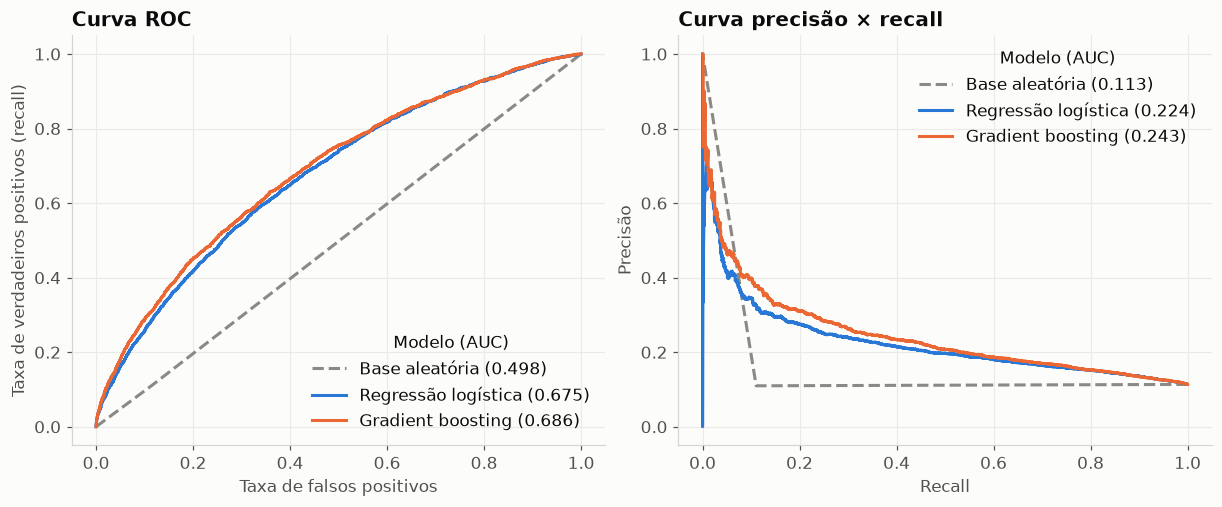

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
cores = {"Base aleatória": CINZA, "Regressão logística": AZUL, "Gradient boosting": LARANJA}
for nome, p in probas.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    prec, rec, _ = precision_recall_curve(y_teste, p)
    estilo = "--" if nome.startswith("Base") else "-"
    ax1.plot(fpr, tpr, estilo, color=cores[nome], lw=2,
             label=f"{nome} ({roc_auc_score(y_teste, p):.3f})")
    ax2.plot(rec, prec, estilo, color=cores[nome], lw=2,
             label=f"{nome} ({average_precision_score(y_teste, p):.3f})")
ax1.set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
ax1.set_title("Curva ROC", loc="left", fontweight="bold")
ax2.set(xlabel="Recall", ylabel="Precisão")
ax2.set_title("Curva precisão × recall", loc="left", fontweight="bold")
ax1.legend(title="Modelo (AUC)", frameon=False, loc="lower right")
ax2.legend(title="Modelo (AUC)", frameon=False, loc="upper right")
fig.savefig(FIGURAS / "10_curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. O modelo na prática: estratificação de risco

Uma AUC isolada é abstrata. A pergunta útil para a equipe é:
**se eu priorizar os pacientes de maior risco, quantas readmissões eu alcanço?**

Ordenamos as internações do teste pelo risco previsto e dividimos em 10 faixas (decis).

Modelo escolhido: Gradient boosting


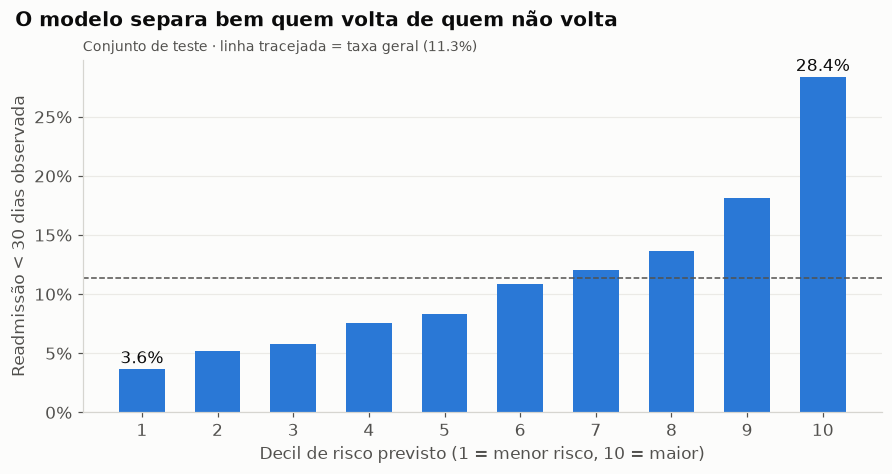

,readmissões alcançadas,taxa no grupo
pacientes priorizados,,
10% de maior risco,25.0%,28.4%
20% de maior risco,41.0%,23.2%
30% de maior risco,53.0%,20.0%


In [7]:
melhor = resultado_teste.drop("Base aleatória")["ROC-AUC"].idxmax()
print(f"Modelo escolhido: {melhor}")
risco = pd.DataFrame({"y": y_teste.values, "p": probas[melhor]})
risco["decil"] = pd.qcut(risco["p"].rank(method="first"), 10, labels=range(1, 11))
decis = risco.groupby("decil", observed=True)["y"].agg(internacoes="size", readmissoes="sum", taxa="mean")

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.bar(decis.index.astype(int), decis["taxa"], width=0.6, color=AZUL)
ax.axhline(y_teste.mean(), color=TINTA_2, ls="--", lw=1)
for d in (1, 10):
    v = decis.loc[d, "taxa"]
    ax.annotate(f"{v:.1%}", (d, v), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.set(xlabel="Decil de risco previsto (1 = menor risco, 10 = maior)", ylabel="Readmissão < 30 dias observada")
fig.suptitle("O modelo separa bem quem volta de quem não volta", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title(f"Conjunto de teste · linha tracejada = taxa geral ({y_teste.mean():.1%})",
             loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "11_decis_de_risco.png", dpi=150, bbox_inches="tight")
plt.show()

decis_cum = decis.iloc[::-1].cumsum()
alcance = pd.DataFrame({
    "pacientes priorizados": [f"{k}0% de maior risco" for k in (1, 2, 3)],
    "readmissões alcançadas": [decis_cum["readmissoes"].iloc[k - 1] / decis["readmissoes"].sum() for k in (1, 2, 3)],
    "taxa no grupo": [decis_cum["readmissoes"].iloc[k - 1] / decis_cum["internacoes"].iloc[k - 1] for k in (1, 2, 3)],
}).set_index("pacientes priorizados")
alcance.style.format("{:.1%}")

### 4.1 Escolha de um ponto de corte

O modelo dá uma probabilidade; a equipe precisa de "alto risco: sim/não".
Escolhemos o corte que marca os **20% de maior risco** como alto risco — um volume
plausível para uma intervenção de enfermagem na alta.

In [8]:
corte = np.quantile(probas[melhor], 0.80)
pred = (probas[melhor] >= corte).astype(int)
vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()
pd.Series({
    "Ponto de corte (probabilidade)": f"{corte:.3f}",
    "Sensibilidade / recall (readmissões identificadas)": f"{vp / (vp + fn):.1%}",
    "Precisão (sinalizados que de fato voltaram)": f"{vp / (vp + fp):.1%}",
    "Verdadeiros positivos": f"{vp:,}",
    "Falsos positivos": f"{fp:,}",
    "Falsos negativos": f"{fn:,}",
    "Verdadeiros negativos": f"{vn:,}",
}).to_frame("valor")

,valor
Ponto de corte (probabilidade),0.584
Sensibilidade / recall (readmissões identificadas),41.0%
Precisão (sinalizados que de fato voltaram),23.2%
Verdadeiros positivos,919
Falsos positivos,"3,036"
Falsos negativos,"1,325"
Verdadeiros negativos,"14,493"


## 5. O que o modelo aprendeu

### 5.1 Regressão logística — razões de chance (odds ratios)

OR > 1 aumenta o risco; OR < 1 reduz. Variáveis numéricas estão padronizadas
(efeito de +1 desvio-padrão).

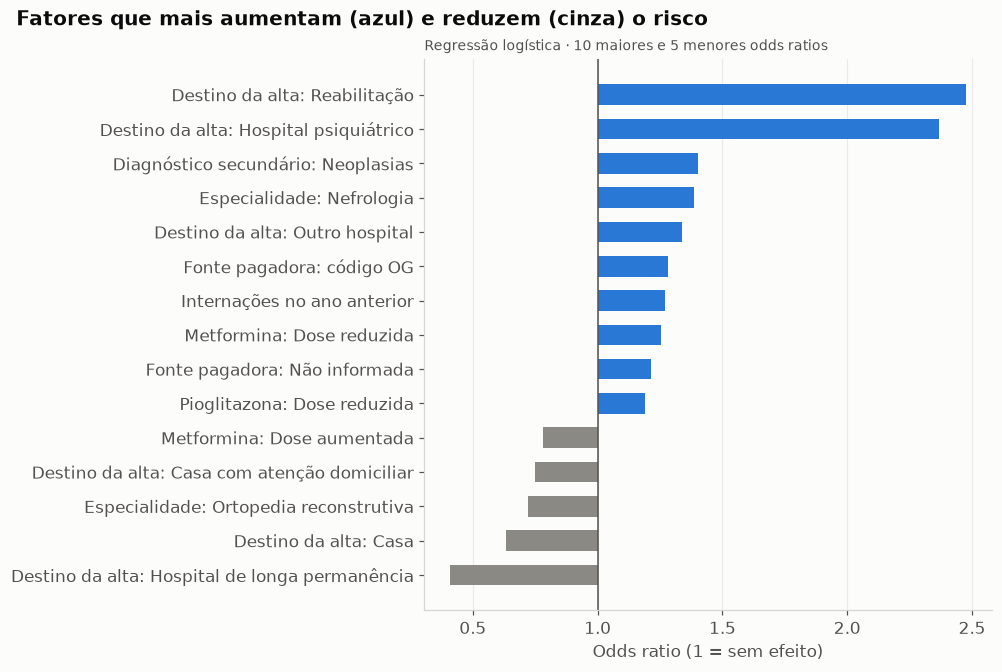

In [9]:
rl = modelos["Regressão logística"]
nomes = rl.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(rl.named_steps["modelo"].coef_[0], index=nomes)
odds = np.exp(coefs).rename("odds_ratio")
odds.index = [nome_feature(n.replace("num__", "").replace("cat__", "")) for n in odds.index]
top = pd.concat([odds.nlargest(10), odds.nsmallest(5)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
cores_barra = [AZUL if v >= 1 else CINZA for v in top]
ax.barh(top.index, top - 1, left=1, color=cores_barra, height=0.6)
ax.axvline(1, color=TINTA_2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio (1 = sem efeito)")
fig.suptitle("Fatores que mais aumentam (azul) e reduzem (cinza) o risco", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title("Regressão logística · 10 maiores e 5 menores odds ratios", loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "12_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Importância por permutação (modelo escolhido)

Quanto a ROC-AUC do teste cai quando embaralhamos cada variável. Quanto maior a queda,
mais o modelo depende dela.

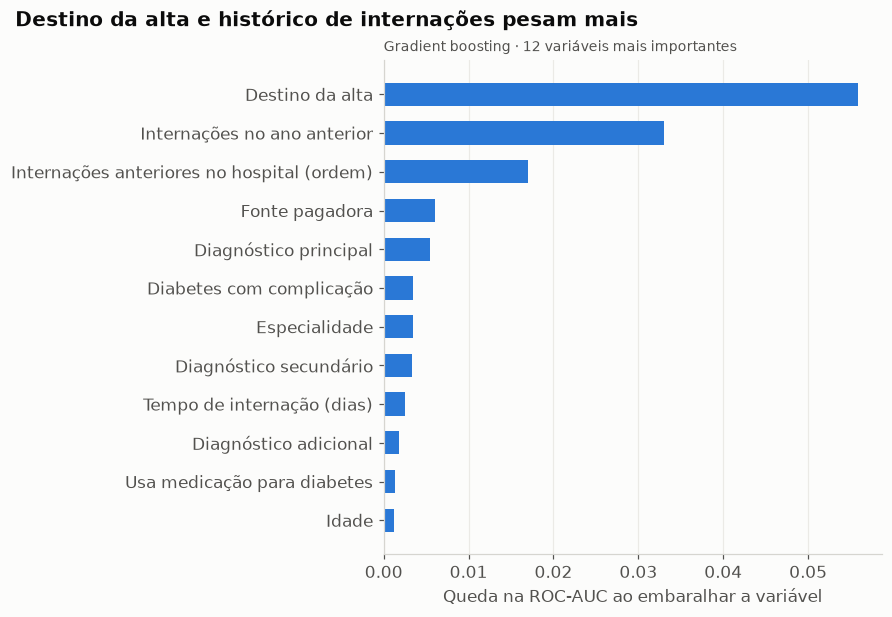

In [10]:
amostra = X_teste.sample(8000, random_state=SEMENTE)
imp = permutation_importance(modelos[melhor], amostra, y_teste.loc[amostra.index],
                             scoring="roc_auc", n_repeats=5, random_state=SEMENTE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=amostra.columns).nlargest(12).sort_values()
importancia.index = importancia.index.map(nome_variavel)

fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
ax.barh(importancia.index, importancia, color=AZUL, height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Queda na ROC-AUC ao embaralhar a variável")
fig.suptitle("Destino da alta e histórico de internações pesam mais", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title(f"{melhor} · 12 variáveis mais importantes", loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "13_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Desempenho por subgrupos (equidade)

Um modelo pode funcionar bem na média e mal para um grupo específico. Avaliamos, no conjunto de
teste, o desempenho por **raça, gênero e faixa etária**, usando o mesmo ponto de corte (20% de maior risco).

A ROC-AUC de cada grupo vem com intervalo de confiança de 95% por *bootstrap* (500 reamostragens):
grupos pequenos têm intervalos largos e não permitem conclusões firmes.

In [11]:
teste = X_teste.assign(y=y_teste.values, escore=probas[melhor])
teste["sinalizado"] = teste["escore"] >= corte
teste["faixa_etaria"] = pd.cut(teste["idade"], [0, 50, 70, 80, 100], right=False,
                               labels=["Menos de 50 anos", "50–69 anos", "70–79 anos", "80+ anos"])
rng = np.random.default_rng(SEMENTE)

def auc_ic(y_g, p_g, n_boot=500):
    y_g, p_g = np.asarray(y_g), np.asarray(p_g)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_g), len(y_g))
        if y_g[i].min() != y_g[i].max():
            aucs.append(roc_auc_score(y_g[i], p_g[i]))
    return np.percentile(aucs, [2.5, 97.5])

linhas = []
for variavel, titulo in [("race", "Raça"), ("gender", "Gênero"), ("faixa_etaria", "Faixa etária")]:
    for grupo, d in teste.groupby(variavel, observed=True):
        if len(d) < 100:
            continue
        inf, sup = auc_ic(d["y"], d["escore"])
        linhas.append({
            "Variável": titulo, "Grupo": rotulo(grupo), "Internações": len(d),
            "Taxa de readmissão": d["y"].mean(),
            "ROC-AUC": roc_auc_score(d["y"], d["escore"]), "IC inf": inf, "IC sup": sup,
            "% sinalizados": d["sinalizado"].mean(),
            "Sensibilidade": d.loc[d["y"] == 1, "sinalizado"].mean(),
            "Precisão": d.loc[d["sinalizado"], "y"].mean(),
        })
subgrupos = pd.DataFrame(linhas)
subgrupos.style.format({"Internações": "{:,}", "Taxa de readmissão": "{:.1%}", "ROC-AUC": "{:.3f}",
                        "IC inf": "{:.3f}", "IC sup": "{:.3f}", "% sinalizados": "{:.1%}",
                        "Sensibilidade": "{:.1%}", "Precisão": "{:.1%}"}).hide(axis="index")

Variável,Grupo,Internações,Taxa de readmissão,ROC-AUC,IC inf,IC sup,% sinalizados,Sensibilidade,Precisão
Raça,Negra (afro-americana),"3,697",10.8%,0.675,0.643,0.704,21.0%,42.1%,21.6%
Raça,Asiática,116,8.6%,0.669,0.489,0.837,13.8%,20.0%,12.5%
Raça,Branca,"14,813",11.7%,0.686,0.672,0.699,20.3%,41.3%,23.8%
Raça,Não informada,447,7.2%,0.663,0.556,0.767,9.8%,21.9%,15.9%
Raça,Hispânica,398,9.0%,0.778,0.691,0.853,16.8%,44.4%,23.9%
Raça,Outra,302,10.3%,0.673,0.575,0.766,13.9%,29.0%,21.4%
Gênero,Feminino,"10,726",11.4%,0.698,0.683,0.714,20.7%,43.0%,23.8%
Gênero,Masculino,"9,047",11.2%,0.673,0.656,0.691,19.2%,38.5%,22.5%
Faixa etária,Menos de 50 anos,"3,198",10.6%,0.737,0.709,0.764,17.3%,47.1%,28.9%
Faixa etária,50–69 anos,"7,823",11.3%,0.701,0.682,0.720,18.4%,41.3%,25.3%


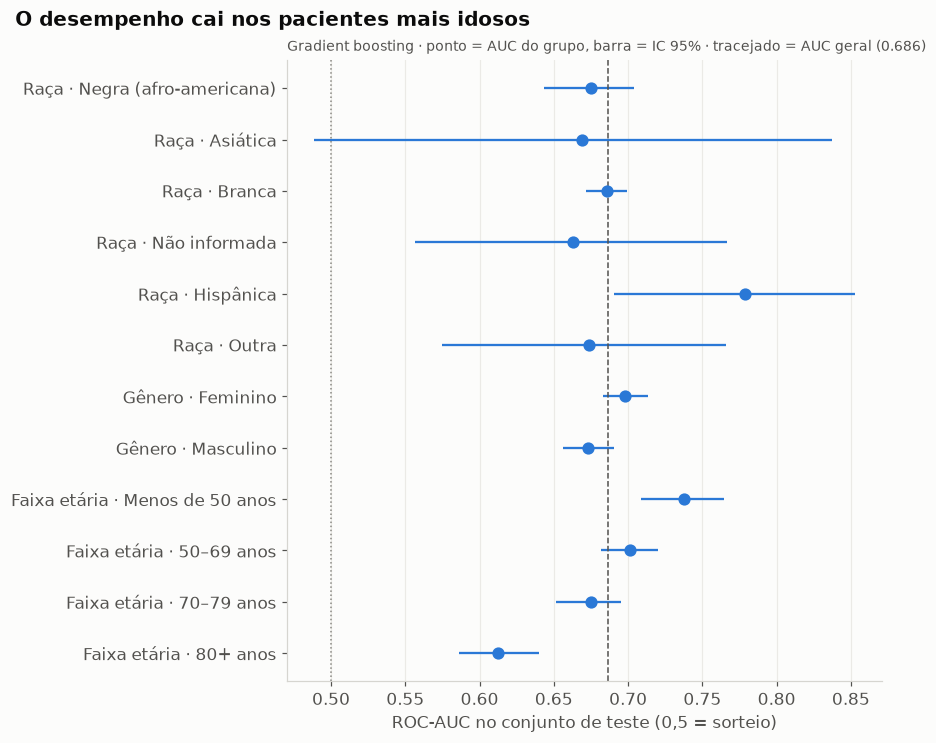

In [12]:
auc_geral = resultado_teste.loc[melhor, "ROC-AUC"]
d = subgrupos.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 0.42 * len(d) + 1.6), layout="constrained")
ax.errorbar(d["ROC-AUC"], d.index, xerr=[d["ROC-AUC"] - d["IC inf"], d["IC sup"] - d["ROC-AUC"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=1.5, markersize=7)
ax.axvline(auc_geral, color=TINTA_2, ls="--", lw=1)
ax.axvline(0.5, color=CINZA, ls=":", lw=1)
ax.set_yticks(d.index, [f"{v} · {g}" for v, g in zip(d["Variável"], d["Grupo"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC no conjunto de teste (0,5 = sorteio)")
fig.suptitle("O desempenho cai nos pacientes mais idosos", x=0.01, ha="left", fontsize=13, fontweight="bold")
ax.set_title(f"{melhor} · ponto = AUC do grupo, barra = IC 95% · tracejado = AUC geral ({auc_geral:.3f})",
             loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "14_subgrupos.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:**
- **Raça e gênero:** nos grupos com volume suficiente (brancos, negros, mulheres e homens), o desempenho
  é parecido, com AUC entre 0,67 e 0,70. Os grupos pequenos têm intervalos muito largos: a AUC dos pacientes
  hispânicos (0,78) parece mais alta, e a dos asiáticos varia de 0,49 a 0,84 — não dá para tirar conclusões
  com tão poucos casos.
- **Idade:** o desempenho **cai com a idade**, de 0,74 abaixo dos 50 anos para **0,61 aos 80 anos ou mais**.
  O intervalo de confiança desse grupo (0,59–0,64) fica inteiro abaixo da AUC geral, então a diferença é
  consistente. A sensibilidade também cai (de 47% para 35%): o escore deixa passar mais idosos que serão readmitidos.
  Uma explicação plausível é que, nos mais idosos, a readmissão depende mais de fragilidade, funcionalidade
  e suporte social, que não estão na base. A implicação prática é discutida na seção 8.4.

## 6. Salvar o modelo final (usado pelo dashboard)

In [13]:
artefato = {
    "modelo": modelos[melhor],
    "nome": melhor,
    "corte_alto_risco": float(corte),
    "colunas": X.columns.tolist(),
    "metricas_teste": resultado_teste.loc[melhor].to_dict(),
    "taxa_base": float(y.mean()),
    # Para o dashboard: valor padrao de cada coluna (mediana / categoria mais comum),
    # categorias possiveis e a distribuicao do risco previsto no teste (percentis).
    "padroes": {c: (float(X[c].median()) if c in numericas else X[c].mode()[0]) for c in X.columns},
    "categorias": {c: sorted(X[c].unique().tolist()) for c in categoricas},
    "percentis_risco": np.quantile(probas[melhor], np.linspace(0, 1, 101)).tolist(),
}
joblib.dump(artefato, MODELOS / "modelo_readmissao.joblib", compress=3)
print(f"Salvo: models/modelo_readmissao.joblib ({melhor})")

Salvo: models/modelo_readmissao.joblib (Gradient boosting)


## 7. Resultados

**Conjunto de teste — pacientes nunca vistos no treino:**
- **Gradient boosting: ROC-AUC 0,686 e PR-AUC 0,243** (regressão logística: 0,675 / 0,224;
  base aleatória: 0,50 / 0,11). Os folds da validação cruzada variam pouco (± 0,002), então o
  resultado é estável. A AUC moderada é típica deste dataset na literatura.
- O decil de maior risco volta **28,4%** das vezes, contra **3,6%** no de menor risco — quase
  8 vezes mais. Priorizar os **20% de maior risco alcança 41% de todas as readmissões**.
- O que mais pesa é o **destino da alta** e o **histórico de internações** (internações no ano
  anterior e internações repetidas no próprio hospital), seguidos do diagnóstico e de diabetes
  com complicação — coerente com a análise exploratória.
- **Por subgrupos**, o desempenho é parecido entre raças e gêneros, mas **cai nos pacientes com 80 anos
  ou mais** (seção 5.3).

A seção 8 discute como esse escore poderia ser usado na prática assistencial e quais são suas limitações.

# 8. Aplicação assistencial do modelo

## 8.1. Do escore de risco à priorização

Apesar do desempenho moderado (ROC-AUC 0,686), o modelo separa bem os grupos de risco: as internações do **decil de maior risco** tiveram **28,4%** de readmissão, contra **3,6%** no decil de menor risco. Os **20% com escores mais altos concentraram 41% de todas as readmissões** do conjunto de teste — o dobro do que se alcançaria escolhendo pacientes ao acaso.

Isso indica que o modelo é mais útil como **instrumento de priorização** do que como ferramenta para prever, paciente a paciente, quem será readmitido. No ponto de corte adotado (20% de maior risco), cerca de **1 em cada 4** pacientes sinalizados é readmitido em até 30 dias — o dobro da taxa geral. Na prática, a equipe poderia usar essa classificação para decidir **quem recebe primeiro** uma avaliação mais detalhada antes da alta, direcionando recursos e intervenções preventivas conforme as necessidades de cada paciente.

O escore é uma estimativa estatística baseada nos padrões de uma base histórica — **não é um diagnóstico nem uma determinação clínica individual**. Como o modelo foi treinado com pesos balanceados, o escore ordena o risco, mas não deve ser lido como a probabilidade real de readmissão.

## 8.2. Intervenções orientadas pelo perfil de risco

Combinando os fatores de maior peso no modelo com os achados da análise exploratória, algumas intervenções poderiam ser priorizadas conforme o perfil do paciente:

| Perfil identificado | Intervenção proposta | Protocolo relacionado* |
|---|---|---|
| Internações ou idas à emergência recorrentes | Revisão do histórico assistencial e avaliação multiprofissional | 8.3.1 |
| Diabetes com complicações ou ajuste de insulina | Monitoramento glicêmico, revisão da insulinoterapia e educação em saúde | 8.3.2 e 8.3.3 |
| Alta para reabilitação ou transferência | Comunicação entre serviços e planejamento da transição do cuidado | 8.3.4 |
| Escore entre os 20% mais altos | Avaliação reforçada antes da alta e acompanhamento definido conforme a necessidade clínica | 8.3.3 e 8.3.4 |
| Pacientes com 80 anos ou mais (qualquer escore) | Avaliação complementar de fragilidade, funcionalidade e suporte familiar, já que o escore identifica pior o risco nessa faixa (seção 5.3) | 8.3.3 e 8.3.4 |

\* Os protocolos completos — objetivos, etapas e indicadores — estão em `01_analise_exploratoria.ipynb`, seção 8.3.

A classificação funcionaria como um **sinalizador** para a equipe, complementando — e nunca substituindo — a avaliação clínica.

## 8.3. Proposta de fluxo assistencial apoiado pelo modelo

Um ponto prático importante: parte das variáveis de maior peso, como o **destino da alta** e o tempo de internação, só é conhecida perto da alta. Por isso, o fluxo prevê dois momentos de uso do escore:

1. **Admissão:** levantamento do histórico de internações, atendimentos de emergência e condições clínicas. Pacientes com internações recorrentes já podem ser sinalizados nesse momento (protocolo 8.3.1).
2. **Planejamento da alta:** com o destino da alta definido, cálculo do escore completo.
3. **Estratificação:** identificação dos pacientes entre os 20% de maior risco.
4. **Avaliação assistencial:** revisão individualizada das necessidades clínicas, funcionais e sociais.
5. **Intervenção:** definição das medidas preventivas conforme o perfil do paciente (tabela 8.2).
6. **Alta:** plano de continuidade do cuidado e encaminhamentos documentados.
7. **Acompanhamento:** monitoramento dos retornos e dos indicadores, para avaliar se a estratégia funciona.

**O escore não deve determinar, adiar ou impedir a alta, nem substituir a avaliação da equipe multiprofissional.** Sua finalidade é apoiar a priorização de avaliações e intervenções.

## 8.4. Limitações para a aplicação prática

- **Dados históricos e de outro país:** a base cobre 1999–2008, em hospitais dos EUA, e não representa necessariamente a população atendida hoje em hospitais brasileiros.
- **Variáveis ausentes:** o desempenho moderado indica que fatores relevantes para a readmissão — suporte social, adesão ao tratamento, acesso a consulta após a alta — não estão nos dados.
- **Associação, não causa:** o modelo identifica quem tem maior chance de retornar, mas não explica por quê. "Não medir HbA1c", por exemplo, não causa readmissão; pode indicar um cuidado menos atento ao diabetes.
- **Escore não calibrado:** o escore ordena os pacientes, mas não estima a probabilidade real de readmissão.
- **Desempenho desigual por idade:** a análise por subgrupos (seção 5.3) mostrou desempenho parecido entre raças e gêneros, mas **menor nos pacientes com 80 anos ou mais** (ROC-AUC de cerca de 0,61, contra 0,74 abaixo dos 50 anos), com menor sensibilidade. Na prática, um escore "habitual" em um idoso deve ser lido com mais cautela: nessa faixa, a readmissão provavelmente depende de fragilidade, funcionalidade e suporte social, que o modelo não enxerga. Por isso, o fluxo proposto inclui uma avaliação complementar para esses pacientes, independentemente do escore. Grupos pequenos (por exemplo, pacientes asiáticos ou hispânicos) têm intervalos de confiança largos e precisariam de mais dados para uma avaliação conclusiva.

Antes de qualquer uso assistencial, seria necessário: validar o modelo em dados atuais e representativos da população de interesse; calibrar as probabilidades; definir o ponto de corte conforme a capacidade de acompanhamento da equipe; repetir a avaliação por subgrupos na população local; estudar a integração com os sistemas hospitalares; e realizar uma avaliação prospectiva da utilidade do modelo na rotina.

## 8.5. Perspectivas de evolução

O projeto pode evoluir de uma análise histórica com capacidade de previsão para uma **ferramenta de apoio à prevenção de readmissões**, em três frentes:

**1. Dados:** atualização da base, inclusão de datas de admissão e alta, comorbidades, indicadores funcionais e sociais e informações sobre a continuidade do cuidado (detalhes em `01_analise_exploratoria.ipynb`, seção 8.4).

**2. Modelo:**
- Calibrar as probabilidades e comparar outras estratégias para lidar com o desbalanceamento.
- Escolher o ponto de corte considerando o objetivo assistencial: um corte mais sensível identifica mais pacientes que voltariam, mas gera mais alertas para a equipe avaliar.
- Fazer validação externa (outros hospitais) e temporal (requer datas, ausentes nesta base).
- Monitorar o desempenho ao longo do tempo e por subgrupo, e testar se variáveis funcionais e sociais reduzem a diferença de desempenho nos pacientes mais idosos.

**3. Assistência:** desenvolver fluxos institucionais de identificação de pacientes, planejamento da alta, educação em saúde e acompanhamento direcionado — e **avaliar os resultados** comparando indicadores de readmissão antes e depois das mudanças, com um desenho de estudo adequado.

Dessa forma, o modelo deixa de ser apenas um exercício de previsão e passa a ser um possível apoio à gestão do cuidado. A redução das readmissões, no entanto, não é um resultado garantido pela adoção do modelo: é um desfecho a ser investigado.

### Referências

As referências completas estão em `01_analise_exploratoria.ipynb`, seção 9. As propostas desta seção se baseiam principalmente em:

- BRASIL. Ministério da Saúde. Política Nacional de Atenção Hospitalar (PNHOSP) — Portaria nº 3.390/2013, consolidada no Anexo XXIV da Portaria de Consolidação nº 2/2017.
- SOCIEDADE BRASILEIRA DE DIABETES. Manejo da hiperglicemia hospitalar em pacientes não críticos (2025).
- SOCIEDADE BRASILEIRA DE DIABETES. Diretrizes clínicas para implantação de programa de controle glicêmico hospitalar (2025).
- AMERICAN DIABETES ASSOCIATION. Standards of Care in Diabetes—2026, seção 16: Diabetes Care in the Hospital.
- STRACK, B. et al. Impact of HbA1c measurement on hospital readmission rates. BioMed Research International, 2014.